# 🎓 Predict Student Dropout and Academic Success

This notebook predicts whether a student will **Dropout**, stay **Enrolled**, or **Graduate**, using academic, demographic and socio-economic data.

**Dataset:** *Predict Students' Dropout and Academic Success* (Realinho et al., UCI Machine Learning Repository). It has 4,424 students, 34 features and 1 target.

**Steps**
1. Imports and setup
2. Load the data
3. Inspect the data
4. Exploratory Data Analysis (EDA)
5. Train/test split
6. Evaluation helper
7. Logistic Regression
8. K-Nearest Neighbors (k tuned with cross-validation)
9. Decision Tree
10. Random Forest + feature importance
11. Support Vector Machine
12. SVM tuned with GridSearchCV
13. Model comparison

## Step 1 — Imports and setup

In [5]:
pip install pandas


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
pip install scikit-learn

   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.9 MB 2.1 MB/s eta 0:00:04
   ----- ---------------------------------- 1.3/8.9 MB 3.2 MB/s eta 0:00:03
   -------- ------------------------------- 1.8/8.9 MB 3.0 MB/s eta 0:00:03
   -------------- ------------------------- 3.1/8.9 MB 3.9 MB/s eta 0:00:02
   --------------------- ------------------ 4.7/8.9 MB 4.7 MB/s eta 0:00:01
   ------------------------- -------------- 5.8/8.9 MB 4.8 MB/s eta 0:00:01
   ----------------------------------- ---- 7.9/8.9 MB 5.5 MB/s eta 0:00:01
   ---------------------------------------- 8.9/8.9 MB 5.5 MB/s  0:00:01
   ---------------------------------------- 0.0/41.3 MB ? eta -:--:--
   -- ------------------------------------- 2.1/41.3 MB 9.8 MB/s eta 0:00:04
   --- ------------------------------------ 3.4/41.3 MB 8.1 MB/s eta 0:00:05
   ---- ----------------------------------- 4.7/41.3 MB 7.3 MB/s eta 0:00:05
   ----- ----------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 101          # one seed for every random step -> reproducible results
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## Step 2 — Load the data
Put `dataset.csv` in the same folder as this notebook.
`encoding="utf-8-sig"` removes the hidden BOM character at the start of the file. Without it, the first column would be named `\ufeffMarital status`.

*Using Google Colab?* Upload the file first with `from google.colab import files; files.upload()`.

In [11]:
df = pd.read_csv("dataset.csv", encoding="utf-8-sig")
df.columns = df.columns.str.strip()
print("Shape:", df.shape)
df.head()

Shape: (4424, 35)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## Step 3 — Inspect the data

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 35 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Nacionality                                     4424 non-null   int64  
 7   Mother's qualification                          4424 non-null   int64  
 8   Father's qualification                          4424 non-null   int64  
 9   Mother's occupation                      

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,6.886980,5.298964,1.00,1.00,8.000000,12.000000,18.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,9.899186,4.331792,1.00,6.00,10.000000,13.000000,17.000000
Daytime/evening attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,2.531420,3.963707,1.00,1.00,1.000000,1.000000,17.000000
Nacionality,4424.0,1.254521,1.748447,1.00,1.00,1.000000,1.000000,21.000000
Mother's qualification,4424.0,12.322107,9.026251,1.00,2.00,13.000000,22.000000,29.000000
Father's qualification,4424.0,16.455244,11.044800,1.00,3.00,14.000000,27.000000,34.000000
Mother's occupation,4424.0,7.317812,3.997828,1.00,5.00,6.000000,10.000000,32.000000


In [13]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print()
print(df["Target"].value_counts())
print()
print((df["Target"].value_counts(normalize=True) * 100).round(1))

Missing values: 0
Duplicate rows: 0

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Target
Graduate    49.9
Dropout     32.1
Enrolled    17.9
Name: proportion, dtype: float64


There are no missing values, and every feature is already numeric.
The target is **imbalanced**: about 50% Graduate, 32% Dropout and 18% Enrolled. Because of this, we report **macro F1** along with accuracy. Macro F1 gives each class equal weight, so the small *Enrolled* class counts as much as the others.

## Step 4 — Exploratory Data Analysis (EDA)

### 4.1 Target distribution

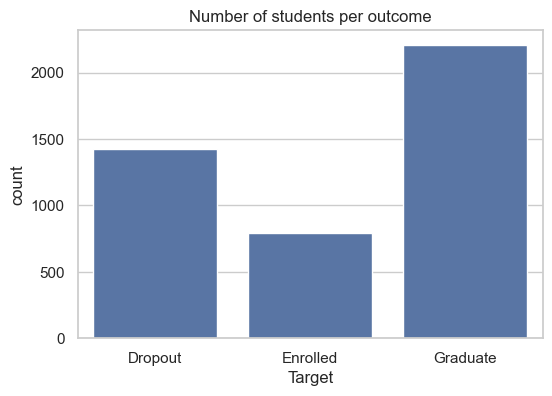

In [14]:
order = ["Dropout", "Enrolled", "Graduate"]
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Target", order=order)
plt.title("Number of students per outcome")
plt.show()

### 4.2 Histograms of all features

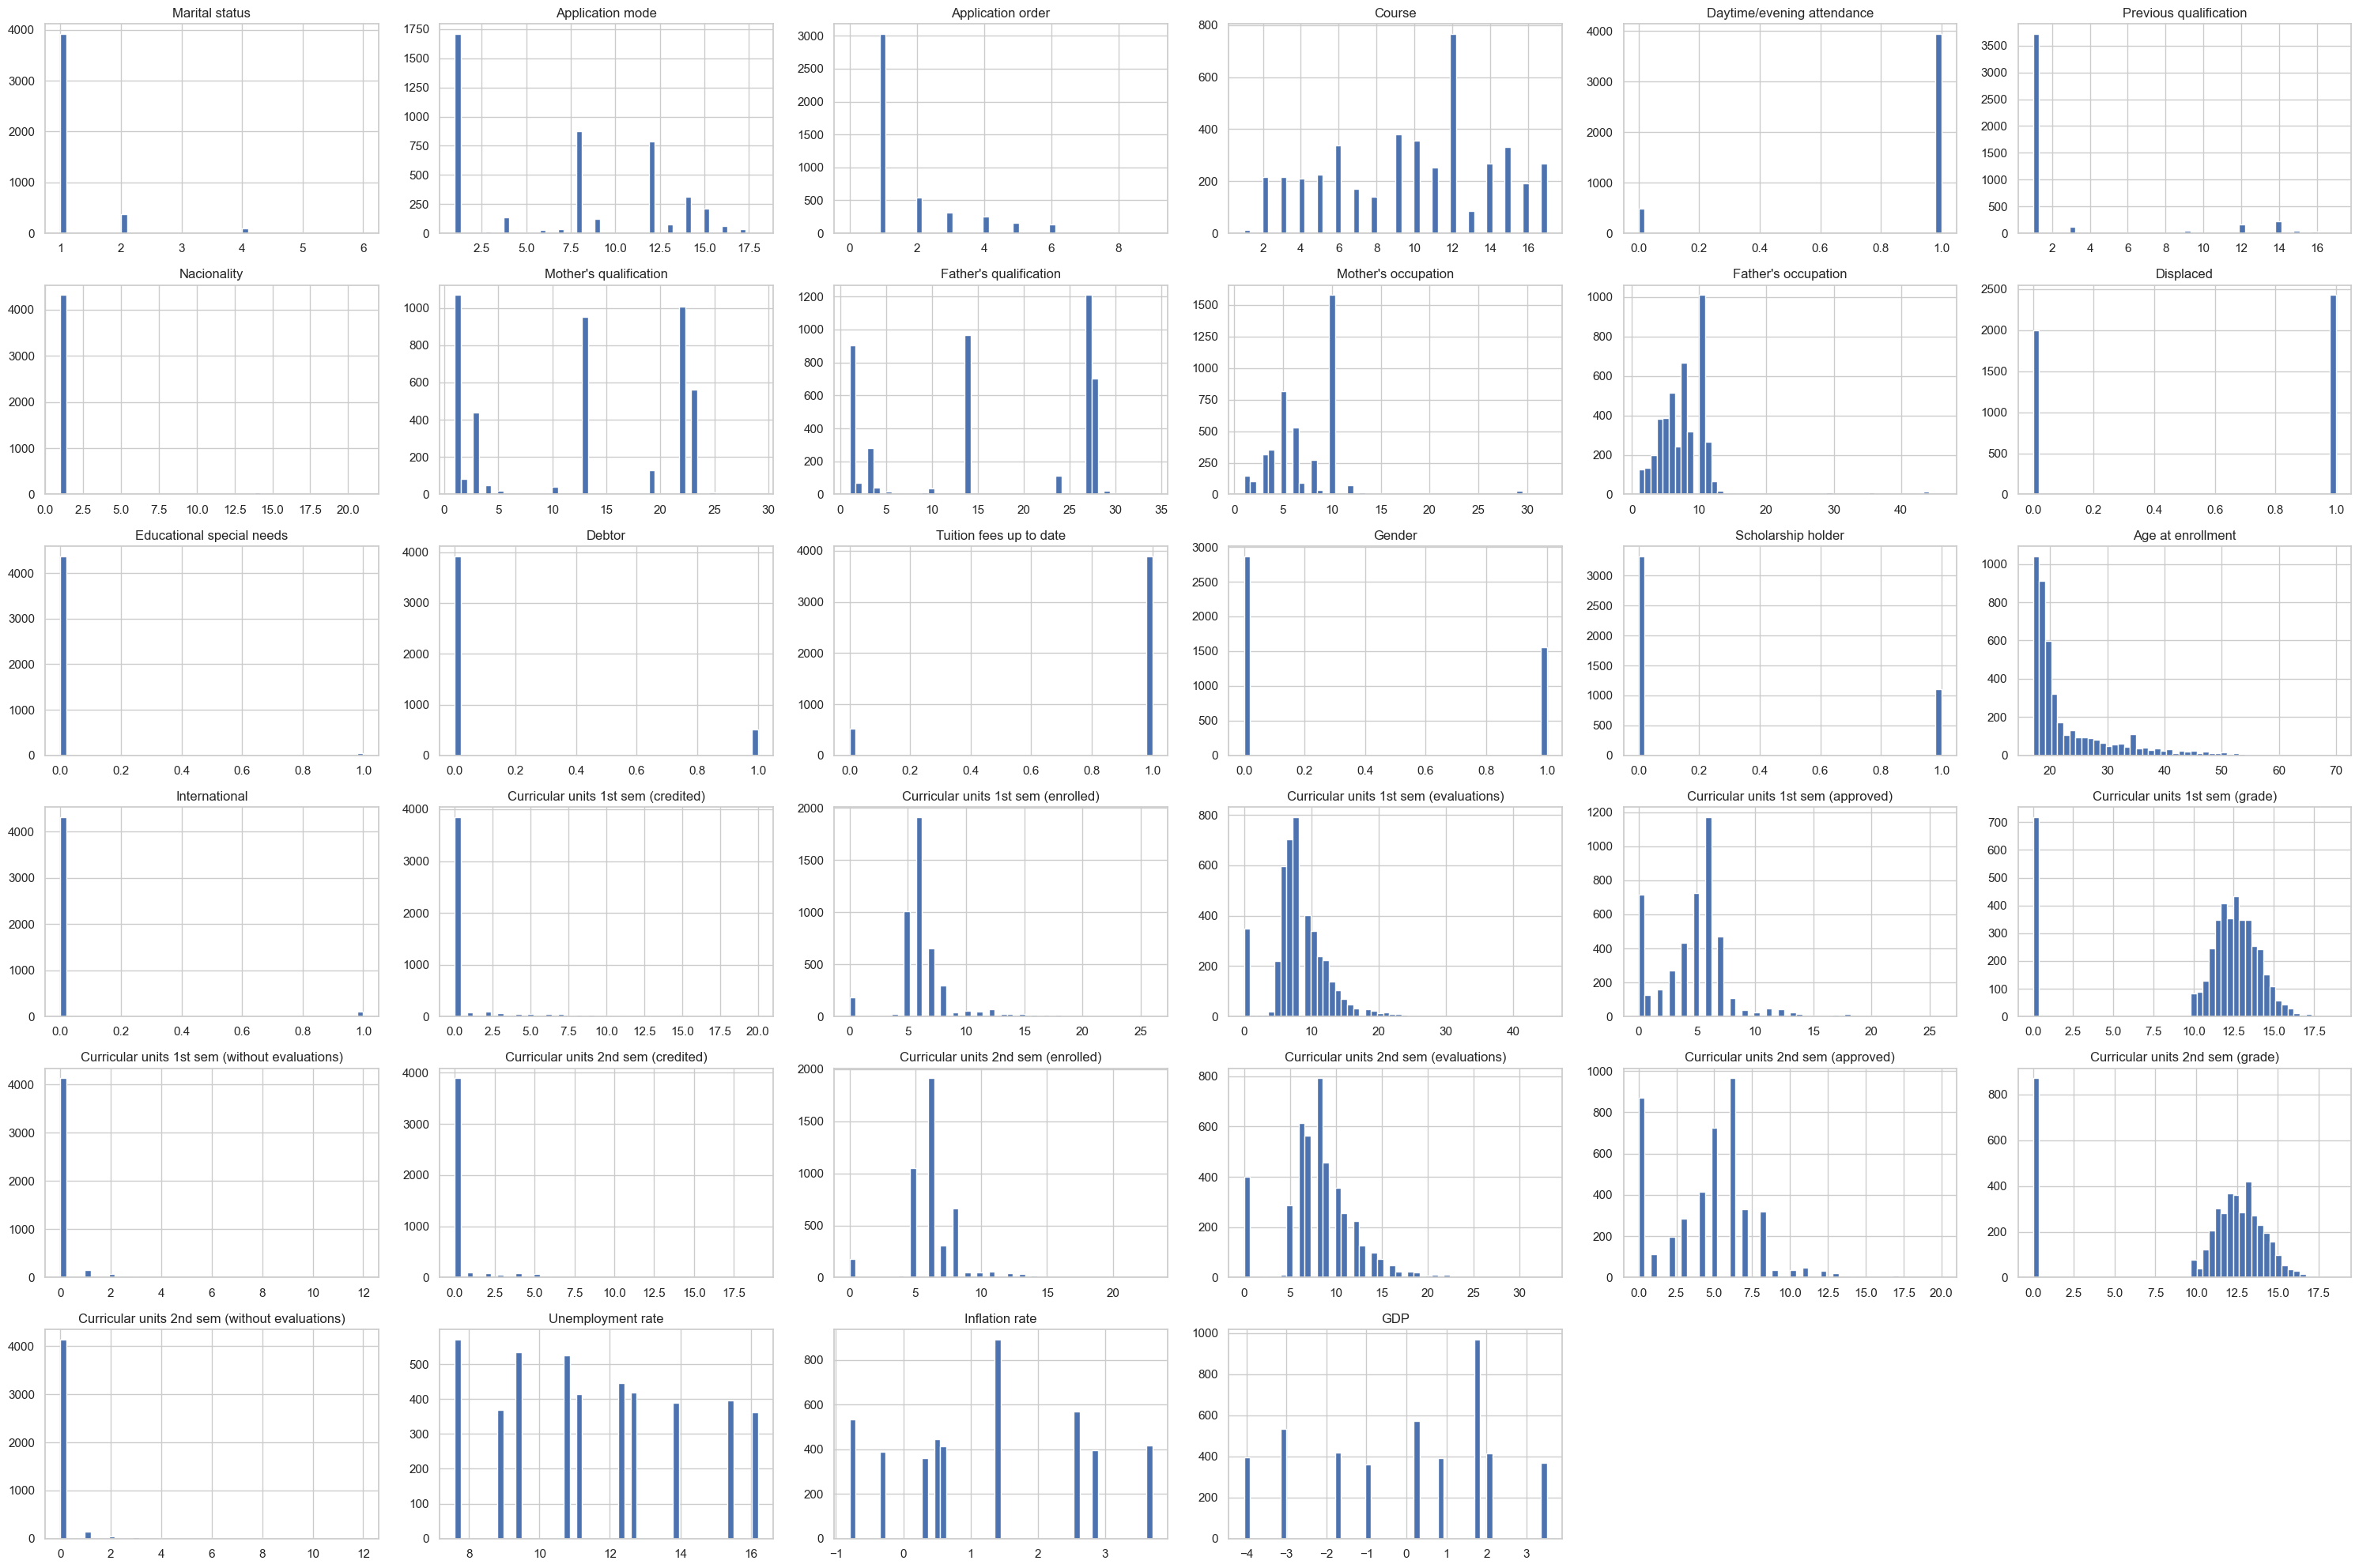

In [15]:
df.hist(bins=50, figsize=(30, 20))
plt.tight_layout()
plt.show()

### 4.3 Correlation heatmap

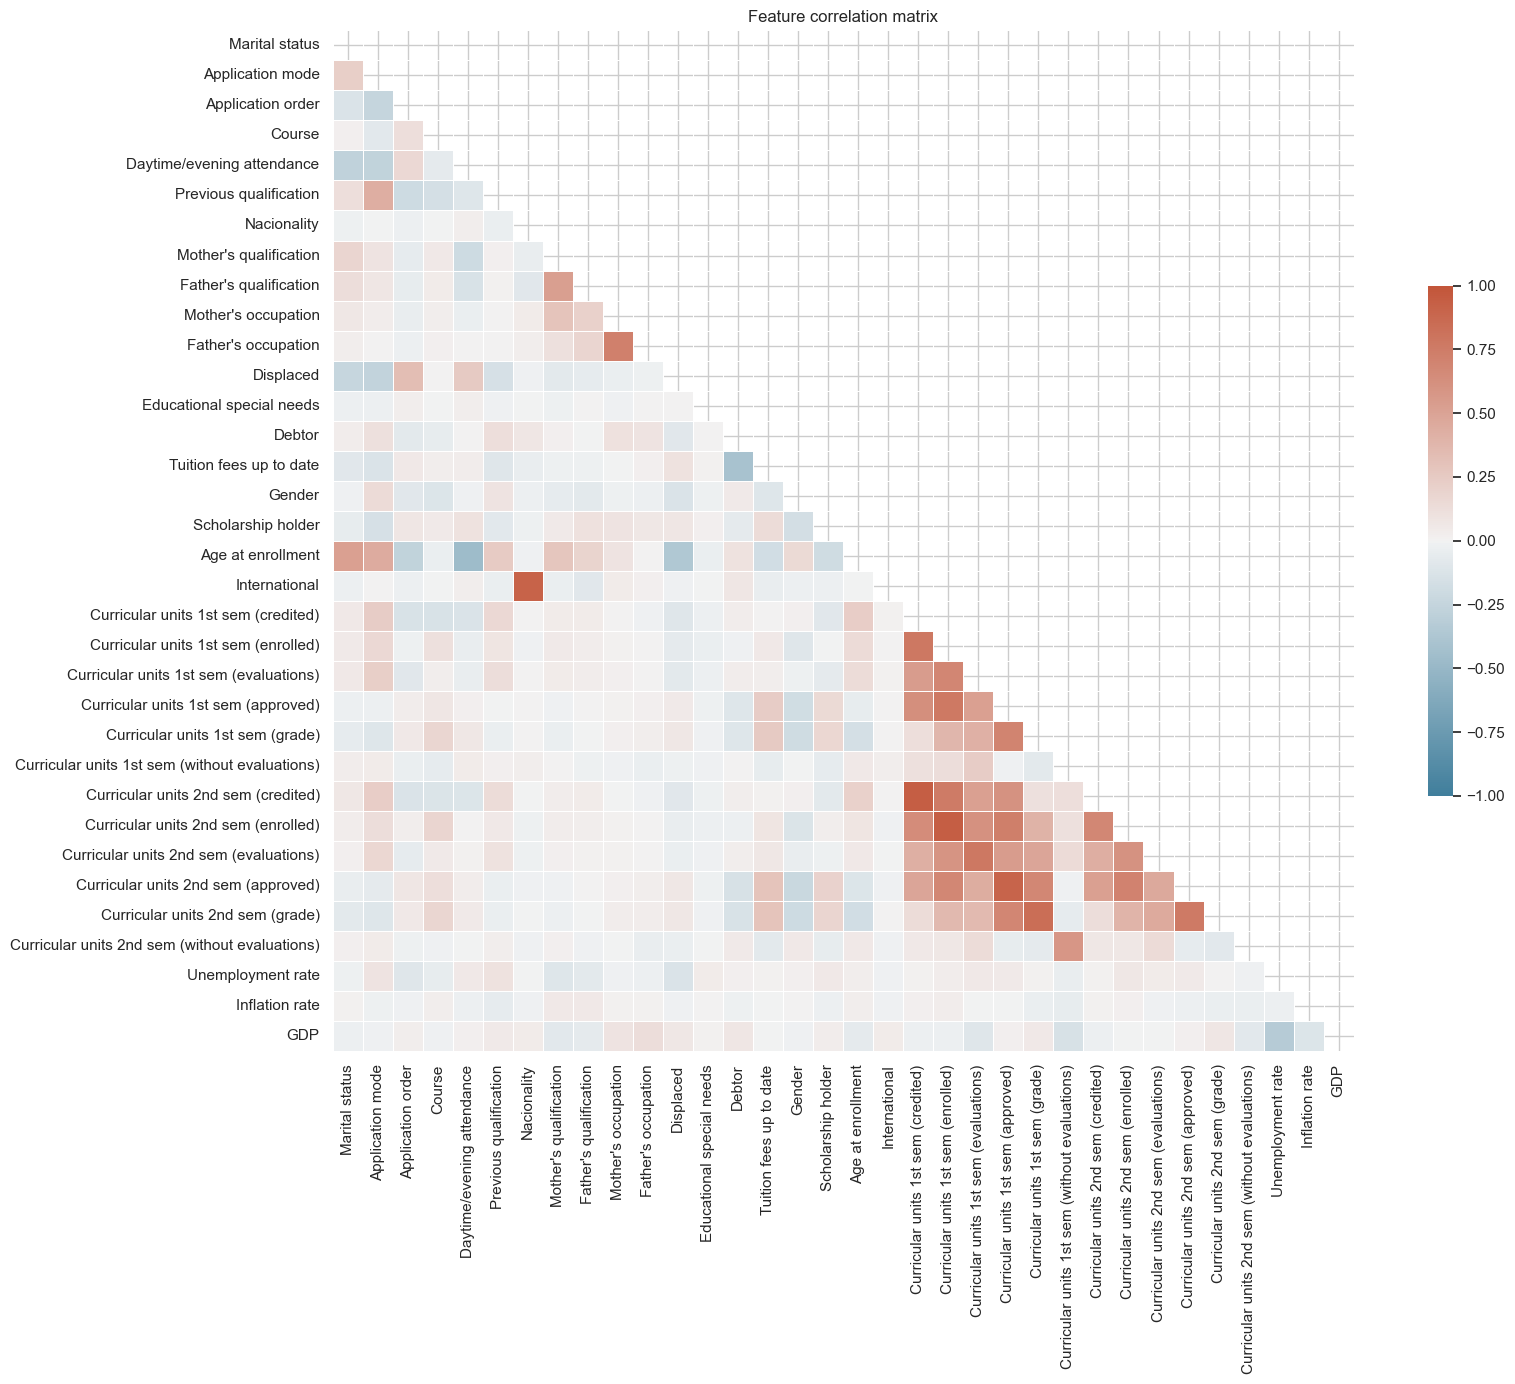

In [16]:
corr = df.corr(numeric_only=True)          # 'Target' is text, so it is left out
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(18, 14))
sns.heatmap(corr, mask=mask, cmap=sns.diverging_palette(230, 20, as_cmap=True),
            vmin=-1, vmax=1, center=0, square=True, linewidths=.5,
            cbar_kws={"shrink": .5})
plt.title("Feature correlation matrix")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=100)
plt.show()

### 4.4 Macroeconomic indicators by outcome

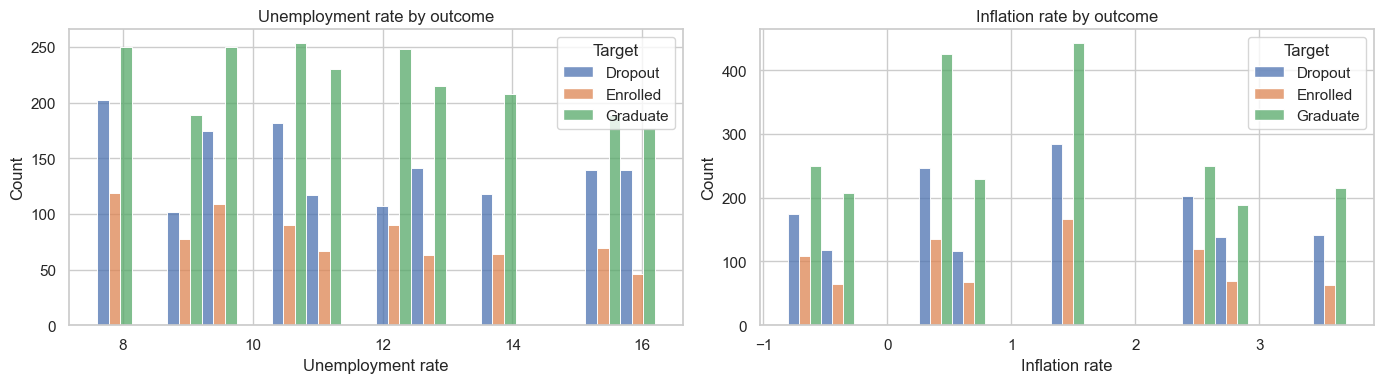

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df, x="Unemployment rate", hue="Target", hue_order=order,
             multiple="dodge", ax=axes[0])
sns.histplot(data=df, x="Inflation rate", hue="Target", hue_order=order,
             multiple="dodge", ax=axes[1])
axes[0].set_title("Unemployment rate by outcome")
axes[1].set_title("Inflation rate by outcome")
plt.tight_layout()
plt.show()

### 4.5 Academic performance by outcome

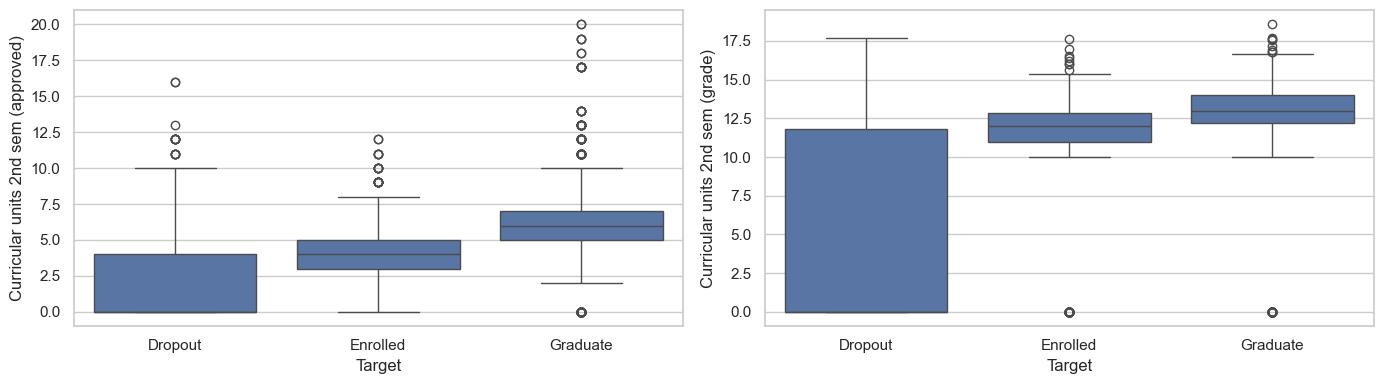

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df, x="Target", y="Curricular units 2nd sem (approved)", order=order, ax=axes[0])
sns.boxplot(data=df, x="Target", y="Curricular units 2nd sem (grade)", order=order, ax=axes[1])
plt.tight_layout()
plt.show()

## Step 5 — Train/test split
We use an 80/20 split. `stratify=y` keeps the same class proportions in both sets.
**Rule:** we never use the test set to choose models or parameters. It is only used for the final score.

In [19]:
X = df.drop("Target", axis=1)
y = df["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (3539, 34)  Test: (885, 34)


## Step 6 — Evaluation helper
A single function prints the same metrics for every model and saves the scores so we can compare them at the end.

In [20]:
results = {}

def evaluate(name, model):
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, average="macro")
    results[name] = {"Accuracy": acc, "Macro F1": f1}

    print(f"===== {name} =====")
    print(f"Accuracy: {acc:.3f}   Macro F1: {f1:.3f}\n")
    print(classification_report(y_test, pred))
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=order),
                           display_labels=order).plot(cmap="Blues")
    plt.title(name)
    plt.grid(False)
    plt.show()

## Step 7 — Logistic Regression
Features such as GDP and grades are on very different scales. We wrap the model in a **pipeline** with `StandardScaler`. The scaler then learns its mean and standard deviation from the training data only, so nothing leaks from the test set.

===== Logistic Regression =====
Accuracy: 0.773   Macro F1: 0.696

              precision    recall  f1-score   support

     Dropout       0.81      0.77      0.79       284
    Enrolled       0.55      0.37      0.44       159
    Graduate       0.80      0.92      0.86       442

    accuracy                           0.77       885
   macro avg       0.72      0.69      0.70       885
weighted avg       0.76      0.77      0.76       885



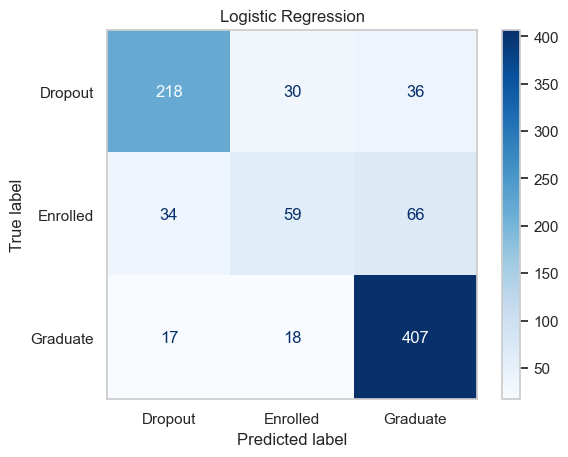

In [21]:
log_model = make_pipeline(StandardScaler(),
                          LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
log_model.fit(X_train, y_train)
evaluate("Logistic Regression", log_model)

## Step 8 — K-Nearest Neighbors
KNN measures distances between students, so **scaling is essential**.
We pick k with **5-fold cross-validation on the training set**. The original notebook picked k using the test set, which made the test score look better than it really is.

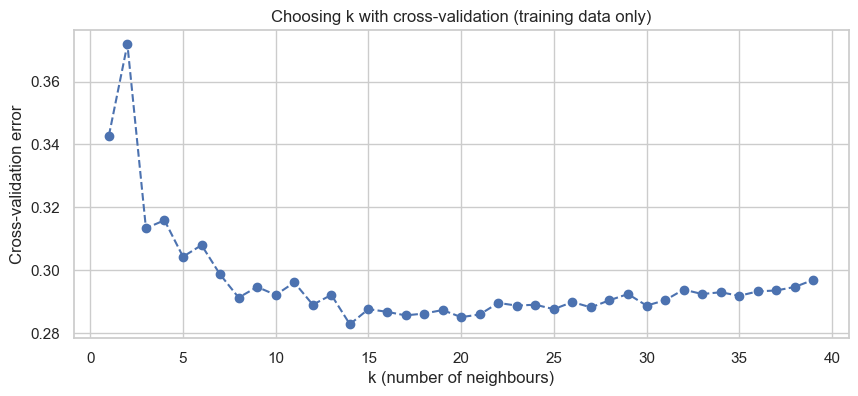

Best k: 14


In [22]:
knn_pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
knn_grid = GridSearchCV(knn_pipe, {"kneighborsclassifier__n_neighbors": range(1, 40)},
                        cv=CV, scoring="accuracy", n_jobs=-1)
knn_grid.fit(X_train, y_train)

cv_error = 1 - knn_grid.cv_results_["mean_test_score"]
plt.figure(figsize=(10, 4))
plt.plot(range(1, 40), cv_error, marker="o", linestyle="--")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Cross-validation error")
plt.title("Choosing k with cross-validation (training data only)")
plt.show()

best_k = knn_grid.best_params_["kneighborsclassifier__n_neighbors"]
print("Best k:", best_k)

===== KNN (k=14) =====
Accuracy: 0.716   Macro F1: 0.612

              precision    recall  f1-score   support

     Dropout       0.87      0.64      0.74       284
    Enrolled       0.39      0.23      0.29       159
    Graduate       0.71      0.94      0.81       442

    accuracy                           0.72       885
   macro avg       0.66      0.60      0.61       885
weighted avg       0.71      0.72      0.69       885



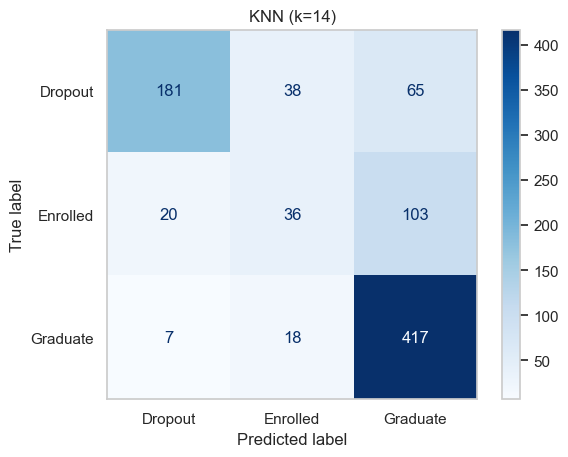

In [23]:
knn_model = knn_grid.best_estimator_
evaluate(f"KNN (k={best_k})", knn_model)

## Step 9 — Decision Tree

===== Decision Tree =====
Accuracy: 0.705   Macro F1: 0.649

              precision    recall  f1-score   support

     Dropout       0.74      0.70      0.72       284
    Enrolled       0.40      0.45      0.42       159
    Graduate       0.81      0.80      0.81       442

    accuracy                           0.71       885
   macro avg       0.65      0.65      0.65       885
weighted avg       0.71      0.71      0.71       885



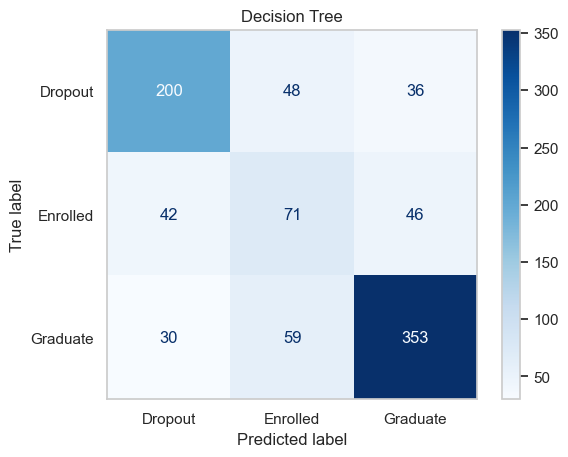

In [24]:
dtree = DecisionTreeClassifier(random_state=RANDOM_STATE)
dtree.fit(X_train, y_train)
evaluate("Decision Tree", dtree)

## Step 10 — Random Forest
Trees don't need scaling. We set `random_state` so the results are the same every run.

===== Random Forest =====
Accuracy: 0.774   Macro F1: 0.706

              precision    recall  f1-score   support

     Dropout       0.83      0.75      0.79       284
    Enrolled       0.56      0.42      0.48       159
    Graduate       0.79      0.92      0.85       442

    accuracy                           0.77       885
   macro avg       0.73      0.69      0.71       885
weighted avg       0.76      0.77      0.76       885



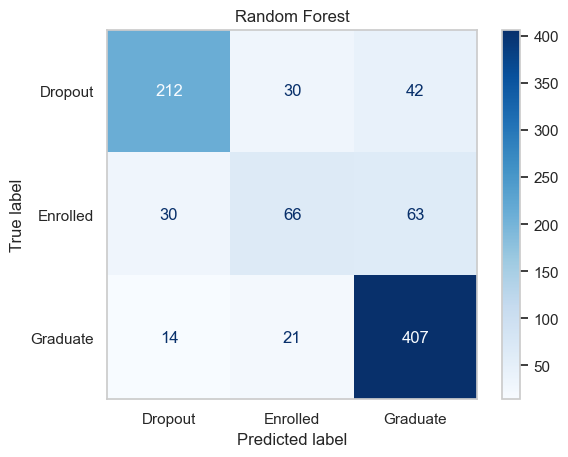

In [25]:
rfc = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rfc.fit(X_train, y_train)
evaluate("Random Forest", rfc)

### 10.1 Which features matter most?

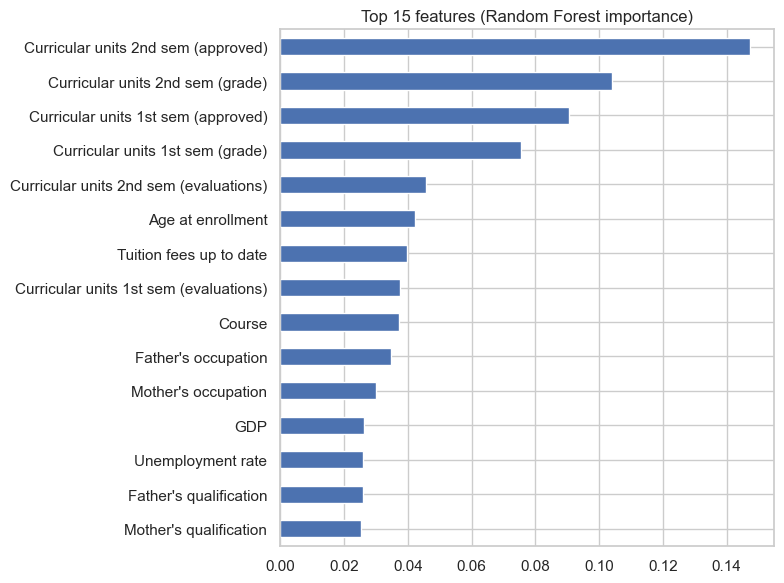

Curricular units 2nd sem (approved)       0.147504
Curricular units 2nd sem (grade)          0.104030
Curricular units 1st sem (approved)       0.090408
Curricular units 1st sem (grade)          0.075388
Curricular units 2nd sem (evaluations)    0.045537
Age at enrollment                         0.042370
Tuition fees up to date                   0.039645
Curricular units 1st sem (evaluations)    0.037544
Course                                    0.037344
Father's occupation                       0.034657
dtype: float64

In [26]:
importances = pd.Series(rfc.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 6))
importances.head(15).sort_values().plot.barh()
plt.title("Top 15 features (Random Forest importance)")
plt.tight_layout()
plt.show()
importances.head(10)

## Step 11 — Support Vector Machine

===== SVM =====
Accuracy: 0.755   Macro F1: 0.670

              precision    recall  f1-score   support

     Dropout       0.82      0.73      0.77       284
    Enrolled       0.51      0.33      0.40       159
    Graduate       0.77      0.93      0.84       442

    accuracy                           0.75       885
   macro avg       0.70      0.66      0.67       885
weighted avg       0.74      0.75      0.74       885



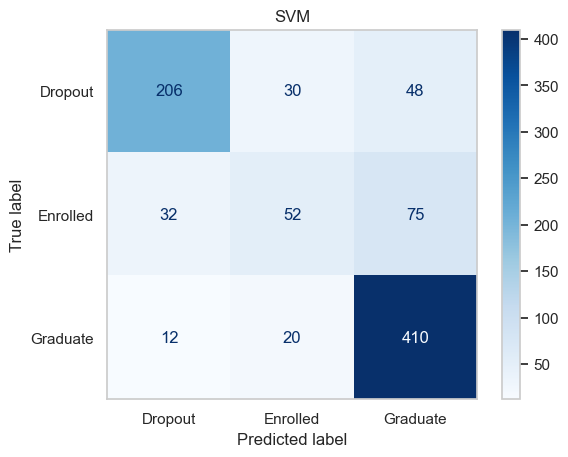

In [27]:
svc_model = make_pipeline(StandardScaler(), SVC(random_state=RANDOM_STATE))
svc_model.fit(X_train, y_train)
evaluate("SVM", svc_model)

## Step 12 — SVM tuned with GridSearchCV
We search over `C` and `gamma` with cross-validation on the training set. The scaler is part of the pipeline, so each CV fold is scaled using only its own training data.

In [28]:
param_grid = {"svc__C": [0.1, 1, 10, 100],
              "svc__gamma": ["scale", 0.1, 0.01, 0.001]}
svm_grid = GridSearchCV(make_pipeline(StandardScaler(), SVC(random_state=RANDOM_STATE)),
                        param_grid, cv=CV, scoring="accuracy", n_jobs=-1)
svm_grid.fit(X_train, y_train)
print("Best parameters:", svm_grid.best_params_)
print(f"Best CV accuracy: {svm_grid.best_score_:.3f}")

Best parameters: {'svc__C': 100, 'svc__gamma': 0.001}
Best CV accuracy: 0.772


===== SVM (tuned) =====
Accuracy: 0.777   Macro F1: 0.712

              precision    recall  f1-score   support

     Dropout       0.83      0.75      0.79       284
    Enrolled       0.57      0.43      0.49       159
    Graduate       0.80      0.92      0.86       442

    accuracy                           0.78       885
   macro avg       0.73      0.70      0.71       885
weighted avg       0.77      0.78      0.77       885



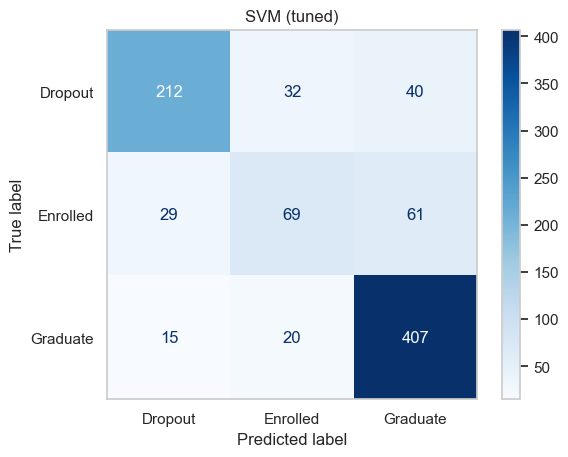

In [29]:
evaluate("SVM (tuned)", svm_grid.best_estimator_)

## Step 13 — Model comparison

In [30]:
summary = pd.DataFrame(results).T.sort_values("Accuracy", ascending=False)
display(summary.style.format("{:.3f}").highlight_max(color="lightgreen"))

summary.plot.barh(figsize=(9, 5))
plt.xlim(0.4, 0.85)
plt.title("Test-set performance by model")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

AttributeError: The '.style' accessor requires jinja2

### Conclusions
* **Tuned SVM (77.7%), Random Forest (77.4%) and Logistic Regression (77.3%)** are essentially tied. With 885 test students, a gap of 0.4 points is only 3–4 predictions, so no model is clearly "the best". KNN (71.6%) and a single Decision Tree (70.5%) are clearly weaker.
* The **Enrolled** class is the hardest to predict for every model. Its recall is only about 0.23–0.45, so macro F1 (0.61–0.71) is well below accuracy.
* By far the most important features are the **2nd- and 1st-semester curricular units approved and their grades**. **Age at enrollment** and **tuition fees up to date** come next. Macroeconomic indicators rank low.
* **Possible next steps:** use `class_weight="balanced"` to improve recall on *Enrolled*, try gradient boosting (e.g. `HistGradientBoostingClassifier`), and use only enrollment-time features if the goal is a very early warning.